# The Normal Curve and Z-Scores

Companion notebook for the [normal curve and z-score note](../../notes/random_variables_and_distributions/normal_curve_and_z_score.md) and its [exercises](../../exercises/random_variables_and_distributions/normal_curve_and_z_score.md).

We use the note's example of fathers' heights, $X\sim N(68.3,\,1.8^2)$ inches. The z-score $z=(x-\mu)/\sigma$ counts standard deviations from the mean, and probabilities are computed through the standard normal CDF $\Phi$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
mu, sigma = 68.3, 1.8

## The empirical rule

The probabilities within $1,2,3$ standard deviations are $2\Phi(k)-1=0.6827,\,0.9545,\,0.9973$ (the rule's rounded values are 68%, 95%, 99.7%).

mu +/- 3 sigma: (62.9, 73.7)  P = 0.9973
mu +/- 2 sigma: (64.7, 71.9)  P = 0.9545
mu +/- 1 sigma: (66.5, 70.1)  P = 0.6827


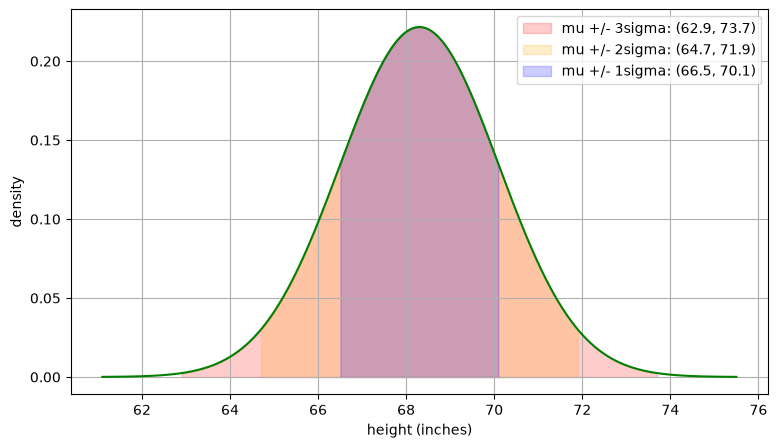

In [2]:
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 800)
pdf = stats.norm.pdf(x, mu, sigma)

plt.figure(figsize=(9, 5))
plt.plot(x, pdf, color="green")
for k, c in [(3, "red"), (2, "orange"), (1, "blue")]:
    lo, hi = mu - k * sigma, mu + k * sigma
    plt.fill_between(x, pdf, where=(x >= lo) & (x <= hi), color=c, alpha=0.2,
                     label=f"mu +/- {k}sigma: ({lo:.1f}, {hi:.1f})")
    print(f"mu +/- {k} sigma: ({lo:.1f}, {hi:.1f})  P = {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}")
plt.xlabel("height (inches)")
plt.ylabel("density")
plt.legend()
plt.grid(True)
plt.show()

## Z-scores

A father of height 71.9 in has $z=3.6/1.8=2$; one of 67.4 in has $z=-0.9/1.8=-0.5$. The z-score is unit-free, so it lets us compare values from different distributions.

In [3]:
def z_score(value, mean, sd):
    return (value - mean) / sd

for h in (71.9, 67.4):
    print(f"height {h}: z = {z_score(h, mu, sigma):+.2f}")

# Comparing across scales: exam A (mu=70, sd=8, score 78) vs exam B (mu=55, sd=5, score 65)
print("exam A z =", z_score(78, 70, 8), " exam B z =", z_score(65, 55, 5))

height 71.9: z = +2.00
height 67.4: z = -0.50
exam A z = 1.0  exam B z = 2.0


## Areas under the curve

$P(67.4\le X\le71.9)=\Phi(2)-\Phi(-0.5)=0.9772-0.3085=0.6687$. We compute this three ways: standard normal CDF of z-scores, the CDF of the original scale, and a simulation.

via z-scores 0.6687   direct 0.6687   simulated 0.6676


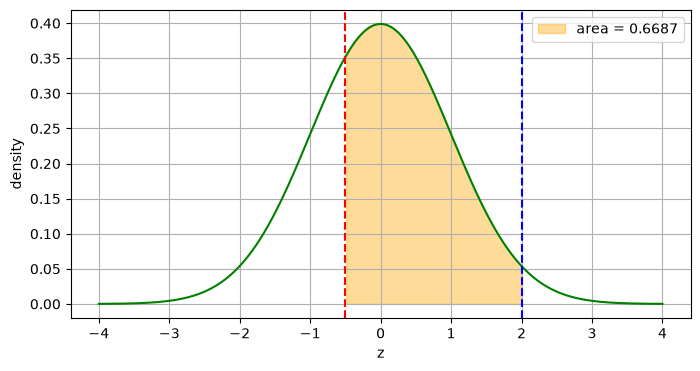

In [4]:
z1, z2 = z_score(67.4, mu, sigma), z_score(71.9, mu, sigma)
via_z = stats.norm.cdf(z2) - stats.norm.cdf(z1)
direct = stats.norm.cdf(71.9, mu, sigma) - stats.norm.cdf(67.4, mu, sigma)
heights = rng.normal(mu, sigma, size=200_000)
sim = np.mean((heights >= 67.4) & (heights <= 71.9))
print(f"via z-scores {via_z:.4f}   direct {direct:.4f}   simulated {sim:.4f}")

zz = np.linspace(-4, 4, 600)
plt.figure(figsize=(8, 4))
plt.plot(zz, stats.norm.pdf(zz), color="green")
plt.fill_between(zz, stats.norm.pdf(zz), where=(zz >= z1) & (zz <= z2), color="orange", alpha=0.4,
                 label=f"area = {via_z:.4f}")
plt.axvline(z1, linestyle="--", color="red")
plt.axvline(z2, linestyle="--", color="blue")
plt.xlabel("z")
plt.ylabel("density")
plt.legend()
plt.grid(True)
plt.show()

## Percentiles: from probability back to a value

Use the inverse CDF (`ppf`) and convert back with $x=\mu+z\sigma$. For the 30th percentile $z=-0.5244$ (the note rounds to $-0.52$), giving $67.36$ in.

In [5]:
for q in (0.30, 0.50, 0.90, 0.975):
    z = stats.norm.ppf(q)
    print(f"{int(q * 1000) / 10:5.1f}th percentile: z = {z:+.4f}, height = {mu + z * sigma:.2f} in")
print("check with the sample:", np.percentile(heights, 30).round(2))

 30.0th percentile: z = -0.5244, height = 67.36 in
 50.0th percentile: z = +0.0000, height = 68.30 in
 90.0th percentile: z = +1.2816, height = 70.61 in
 97.5th percentile: z = +1.9600, height = 71.83 in
check with the sample: 67.35


## Standardizing a dataset

Subtracting the sample mean and dividing by the sample standard deviation gives z-scores with mean 0 and sample variance 1. For the data $4,8,6,5,12$ the largest value has $z=5/\sqrt{10}\approx1.58$.

In [6]:
data = np.array([4, 8, 6, 5, 12], dtype=float)
z = (data - data.mean()) / data.std(ddof=1)
print("mean", data.mean(), " sd", data.std(ddof=1).round(4))
print("z-scores:", z.round(3))
print("mean of z:", z.mean().round(10), " sample variance of z:", z.var(ddof=1).round(10))

mean 7.0  sd 3.1623
z-scores: [-0.949  0.316 -0.316 -0.632  1.581]
mean of z: 0.0  sample variance of z: 1.0


## Takeaways

* $z=(x-\mu)/\sigma$ standardizes any normal variable to $N(0,1)$.
* The empirical rule gives quick checks; use $\Phi$ and `ppf` for exact answers.
* Standardized data has mean 0 and standard deviation 1 by construction, whatever the original distribution.